# Stage 2: cellular neighbourhoods (niches)

Final Stage 1 objects → neighbour fractions of `cell_class_threshold` within 50 µm → CLR transform → weighted K-means (K = 15) → named niches.

The analysis code is the same as in the original niche analysis notebook. This copy reads the final Stage 1 objects, saves every figure to `FIGURE_DIR` under its own name, checks the niche names against the clusters, and compares the result with the original combined object.

In [1]:
import os, random, numpy as np
SEED = 23
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
random.seed(SEED)
np.random.seed(SEED)

## Parameters

In [2]:
STAGE1_DIR = "/path/to/stage1_output"  # one subfolder per sample, with <sample>.h5ad
OUTPUT_DIR = "/path/to/stage2_output"
FIGURE_DIR = os.path.join(OUTPUT_DIR, "figures")
# The original combined object, used only for the check at the end; set to None to skip it
ORIGINAL_COMBINED = "/path/to/original_combined.h5ad"

radius = 50.0        # µm
pseudocount = 1e-3
K = 15               # chosen from the K selection below
N_INIT = 12
# K selection streams all cells for each K from 8 to 25 and takes several hours; its results do not change the final fit
RUN_K_SELECTION = False

sample_names = [
    "MH065_314", "MH074_314", "MH096_314", "MH097_314",
    "MH099_314", "MH104_314", "MH106_314", "MH107_314",
    "MH065_480", "MH074_480", "MH096_480", "MH097_480",
    "MH099_480", "MH104_480", "MH106_480", "MH107_480"
]

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import squidpy as sq
from scipy import sparse
from scipy.stats import zscore
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

os.makedirs(FIGURE_DIR, exist_ok=True)

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


## 1. Load the final Stage 1 objects

Stage 2 uses only `cell_class_threshold`, the cell coordinates and the cell IDs, so only these are loaded.

In [4]:
def load_stage1(sample):
    path = os.path.join(STAGE1_DIR, sample, f"{sample}.h5ad")
    full = sc.read_h5ad(path, backed="r")
    ad = sc.AnnData(obs=full.obs[["cell_class_threshold"]].copy())
    ad.obsm["spatial"] = np.asarray(full.obsm["spatial"]).copy()
    full.file.close()
    return ad


adata_list = [load_stage1(sample) for sample in sample_names]
assert len(adata_list) == len(sample_names)
print(pd.Series({s: ad.n_obs for s, ad in zip(sample_names, adata_list)}, name="cells"))

MH065_314    154206
MH074_314    145717
MH096_314    174784
MH097_314    282289
MH099_314    141568
MH104_314    101830
MH106_314    153269
MH107_314     97631
MH065_480     93891
MH074_480    264689
MH096_480    458968
MH097_480    194626
MH099_480    144282
MH104_480    162903
MH106_480    146148
MH107_480    214226
Name: cells, dtype: int64


## 2. Neighbour fractions within 50 µm

In [5]:
# ---------------------------------------------------------------------
# helper to build a neighbour-fraction AnnData for ONE slide
# ---------------------------------------------------------------------
def build_neigh_anndata(ad, sample, radius=50.0):
    ad = ad.copy()
    ad.obs["sample"] = sample
    ad.obs["cell_id"] = ad.obs_names.values  # keep original id # *** 
    
    # radius graph
    sq.gr.spatial_neighbors(
        ad, coord_type="generic",
        radius=radius, #have checked that radius is in micrometer
        delaunay=False,
        key_added="spatial",
        set_diag=False #(by default to exclude self-interaction)
    )
    adj = ad.obsp["spatial_connectivities"]          # CSR (spots × spots)

    # one-hot cell-type matrix
    labels  = ad.obs["cell_class_threshold"].astype(str)
    ct_ohe  = pd.get_dummies(labels)                  # dense → convert to CSR
    ct_mat  = sparse.csr_matrix(ct_ohe.values)

    # neighbour counts → fractions
    counts   = adj @ ct_mat
    row_sum  = np.asarray(counts.sum(1)).ravel()
    
    keep     = row_sum > 0                           # drop isolated / edge
    counts   = counts[keep]
    row_sum  = row_sum[keep]
    ids_keep = ad.obs_names[keep]

    frac     = counts.multiply(1 / row_sum[:, None]) # 0–1, still CSR
    
    ad_n = sc.AnnData(
        X   = frac,
        obs = ad.obs.loc[ids_keep, ["sample","cell_id","cell_class_threshold"]].copy(), # add cell id *****
        var = pd.DataFrame(index=ct_ohe.columns )
    )
    ad_n.obsm["spatial"] = ad.obsm["spatial"][keep].copy()
    ad_n.uns["spatial_params"] = {"radius": radius} ## ***
    ad_n.obs_names = ids_keep
    return ad_n

In [6]:
# ---------------------------------------------------------------------
# 1. build neighbour AnnDatas for all slides
# ---------------------------------------------------------------------
neigh_list = [build_neigh_anndata(ad, name, radius) for ad, name in zip(adata_list, sample_names)] # version 3

# ---------------------------------------------------------------------
# 2. concatenate -> one matrix (cells × cell-types)
# ---------------------------------------------------------------------
combined = sc.concat(
    neigh_list,
    join           = "outer",    # union of cell-types
    label          = "sample",   # sample ID preserved
    keys           = sample_names,
    fill_value     = 0.0,
    index_unique   = "-", #to ensure each cell label is unique
    merge          = "first"     # keep unique .uns entries
)

# Freeze row and column order 
combined = combined[combined.obs_names.sort_values(), :].copy()
combined = combined[:, sorted(list(combined.var_names))].copy()

## 3. CLR transform and scaling

In [7]:
X = combined.X.toarray() if sparse.issparse(combined.X) else np.asarray(combined.X)
X = X.astype(np.float32)

# CLR transform
X += pseudocount
geom_mean = np.exp(np.mean(np.log(X), axis=1, keepdims=True))
X_clr = np.log(X / geom_mean)

# center + scale
scaler = StandardScaler(with_mean=True, with_std=True)
X_std = scaler.fit_transform(X_clr)

combined.obsm['X_std'] = X_std.astype(np.float32)

## 4. K selection (optional)

Elbow, centroid stability and held-out error for K = 8–25, using MiniBatchKMeans. K = 15 was chosen from these. K = 8 had higher centroid stability (0.8635 vs 0.8395 at K = 15).

In [8]:
# ---------------------------------------------------------------------
# DECIDING ON K values
# ---------------------------------------------------------------------
# ---- K selection for 3M cells: elbow + stability + held-out ----
# Requires: scikit-learn >= 1.2, numpy, matplotlib, scipy
import numpy as np
from sklearn.cluster import MiniBatchKMeans, KMeans
from sklearn.metrics.pairwise import cosine_similarity
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt

# ---------- helpers ----------
def rng_choice(n, size, rng, replace=False):
    size = min(size, n)
    return rng.choice(n, size=size, replace=replace)

def knee_point(pts):
    # pts: (K, y) with K increasing
    K = pts[:, 0].astype(float)
    y = pts[:, 1].astype(float)
    x1, y1, x2, y2 = K[0], y[0], K[-1], y[-1]
    den = np.hypot(x2 - x1, y2 - y1)
    d = np.abs((y2 - y1) * K - (x2 - x1) * y + x2 * y1 - y2 * x1) / den
    return int(K[np.argmax(d)])

def minibatch_fit_stream(X, K, batch_size=8192, epochs=2, seed=0, n_init=3, sample_weight=None):
    """Stream data in mini-batches using partial_fit (memory safe)."""
    rng = np.random.RandomState(seed)
    n = X.shape[0]
    km = MiniBatchKMeans(n_clusters=K, random_state=seed, n_init=n_init, batch_size=batch_size)
    # Initialize with a small random subset for robust starts
    init_idx = rng_choice(n, min(10000, n), rng)
    km.partial_fit(X[init_idx], sample_weight=None if sample_weight is None else sample_weight[init_idx])
    # Epochs over the whole dataset
    for _ in range(epochs):
        order = rng.permutation(n)
        for start in range(0, n, batch_size):
            sl = order[start:start + batch_size]
            km.partial_fit(X[sl], sample_weight=None if sample_weight is None else sample_weight[sl])
    return km

def per_point_inertia(km, X_eval):
    # sklearn's score returns negative SSE; divide by N to get mean SSE per point
    return -km.score(X_eval) / len(X_eval)

def centroid_stability(X, K, n_sub=100_000, seed=0, batch_size=8192):
    rng = np.random.RandomState(seed)
    idx1 = rng_choice(X.shape[0], n_sub, rng)
    idx2 = rng_choice(X.shape[0], n_sub, rng)
    km1 = MiniBatchKMeans(K, random_state=seed, n_init=3, batch_size=batch_size).fit(X[idx1])
    km2 = MiniBatchKMeans(K, random_state=seed + 1, n_init=3, batch_size=batch_size).fit(X[idx2])
    S = cosine_similarity(km1.cluster_centers_, km2.cluster_centers_)
    r, c = linear_sum_assignment(-S)  # maximize total similarity
    return float(S[r, c].mean())

def heldout_error(X_train, X_val, K, seed=0, batch_size=8192):
    km = MiniBatchKMeans(K, random_state=seed, n_init=3, batch_size=batch_size).fit(X_train)
    return per_point_inertia(km, X_val)

# ---------- main driver ----------
def evaluate_K_range(
    X,
    Ks=range(6, 31),
    seed=0,
    batch_size=8192,
    epochs=2,
    eval_size=200_000,
    stability_sub=100_000,
    heldout_train=500_000,
    heldout_val=500_000,
    sample_weight=None
):
    rng = np.random.RandomState(seed)
    n = X.shape[0]
    eval_idx = rng_choice(n, eval_size, rng)
    X_eval = X[eval_idx]

    # held-out splits
    tr_idx = rng_choice(n, heldout_train, rng, replace=False)
    va_pool = np.setdiff1d(np.arange(n), tr_idx, assume_unique=False)
    va_idx = rng_choice(len(va_pool), heldout_val, rng, replace=False)
    X_tr, X_va = X[tr_idx], X[va_pool[va_idx]]

    inertias = []
    stabilities = []
    val_errors = []

    for K in Ks:
        # streamed fit for elbow
        km = minibatch_fit_stream(
            X, K, batch_size=batch_size, epochs=epochs, seed=seed, n_init=3,
            sample_weight=sample_weight
        )
        inertias.append(per_point_inertia(km, X_eval))
        # centroid stability on split halves
        stabilities.append(centroid_stability(X, K, n_sub=stability_sub, seed=seed, batch_size=batch_size))
        # held-out recon error
        val_errors.append(heldout_error(X_tr, X_va, K, seed=seed, batch_size=batch_size))
        print(f"K={K:2d}  inertia={inertias[-1]:.4f}  stability={stabilities[-1]:.4f}  heldout={val_errors[-1]:.4f}")

    Ks = np.array(list(Ks))
    inertias = np.array(inertias)
    stabilities = np.array(stabilities)
    val_errors = np.array(val_errors)

    # knee from inertia + from heldout
    elbow_pts = np.column_stack([Ks, inertias])
    heldout_pts = np.column_stack([Ks, val_errors])
    k_elbow = knee_point(elbow_pts)
    k_val_knee = knee_point(heldout_pts)

    # plotting
    fig, axs = plt.subplots(3, 1, figsize=(7, 12))
    axs[0].plot(Ks, inertias, marker='o')
    axs[0].axvline(k_elbow, linestyle='--')
    axs[0].set_title("Elbow: mean SSE per point vs K")
    axs[0].set_xlabel("K"); axs[0].set_ylabel("Mean SSE")

    axs[1].plot(Ks, stabilities, marker='o')
    axs[1].set_title("Centroid stability (mean cosine similarity)")
    axs[1].set_xlabel("K"); axs[1].set_ylabel("Stability")

    axs[2].plot(Ks, val_errors, marker='o')
    axs[2].axvline(k_val_knee, linestyle='--')
    axs[2].set_title("Held-out reconstruction error vs K")
    axs[2].set_xlabel("K"); axs[2].set_ylabel("Mean SSE (held-out)")

    plt.tight_layout()
    return {
        "Ks": Ks,
        "inertia": inertias,
        "stability": stabilities,
        "heldout": val_errors,
        "knee_inertia": k_elbow,
        "knee_heldout": k_val_knee,
    }

# ---------- example usage ----------
# X_std: your CLR+standardized features (numpy array or scipy sparse -> convert to np.array)
# w: optional per-cell weights (e.g., inverse sample-frequency), shape (N,)
# Make sure X_std is float32 to reduce memory.
# results = evaluate_K_range(X_std, Ks=range(8, 26), seed=42, sample_weight=w)
# print("Elbow knee:", results["knee_inertia"], "Held-out knee:", results["knee_heldout"])

# ---------- final fit at chosen K (e.g., 15) ----------
def final_refit_and_labels(X, K, w=None, seed=42, use_full_kmeans=False):
    """
    Refit the final model on ALL cells.
    - If use_full_kmeans=True: use standard KMeans (exact Lloyd).
    - Else: MiniBatchKMeans for speed; virtually identical centroids at this scale.
    """
    if use_full_kmeans:
        km = KMeans(n_clusters=K, random_state=seed, n_init=10)
        # KMeans supports sample_weight in fit (sklearn >= 1.2)
        labels = km.fit_predict(X, sample_weight=w)
    else:
        km = MiniBatchKMeans(n_clusters=K, random_state=seed, n_init=10, batch_size=8192)
        labels = km.fit_predict(X, sample_weight=w)
    return km, labels

In [9]:
sec = combined.obs["sample"].to_numpy()
sec_counts = pd.Series(sec).value_counts()
w = 1.0 / sec_counts[sec].to_numpy()

if RUN_K_SELECTION:
    results = evaluate_K_range(X_std, Ks=range(8, 26), seed=42, sample_weight=w)
    plt.savefig(os.path.join(FIGURE_DIR, "K_selection.pdf"), bbox_inches="tight")
    plt.show()

## 5. Weighted K-means

Each cell is weighted by 1 / (cells in its sample), so that every sample contributes equally.

In [10]:
km = KMeans(n_clusters=K,
            random_state=SEED, n_init=N_INIT,
            algorithm="lloyd", #default
            max_iter=300, #default
            tol=1e-4 #default
           ).fit(X_std, sample_weight=w)
combined.obs["niche_CLR_km"] = km.labels_.astype(str)

In [11]:
import pandas as pd

# Build label map with a key
lbl = combined.obs[["sample", "cell_id", "niche_CLR_km"]].copy()

# check duplicates
dup_src = lbl.duplicated(["sample","cell_id"]).sum()
assert dup_src == 0, f"combined has {dup_src} duplicate (sample,cell_id) rows"

label_map = lbl.set_index(["sample","cell_id"])["niche_CLR_km"]

summary = []
for ad in neigh_list:
    # check for duplicates in target
    dup_tgt = ad.obs.duplicated(["sample","cell_id"]).sum()
    assert dup_tgt == 0, f"{ad.obs['sample'].iat[0]} has {dup_tgt} duplicate (sample,cell_id)"

    keys = pd.MultiIndex.from_frame(ad.obs[["sample","cell_id"]])
    mapped = label_map.reindex(keys)

    n_na = int(mapped.isna().sum())
    summary.append({
        "sample": ad.obs["sample"].iat[0],
        "n_total": ad.n_obs,
        "n_unmapped": n_na,
        "pct_unmapped": 100*n_na/ad.n_obs
    })

    # policy: fail loudly OR keep as 'unmapped'
    assert n_na == 0, f"{ad.obs['sample'].iat[0]} has {n_na} unmapped cells"
    # ad.obs["niche_CLR_km"] = mapped.fillna("unmapped").astype(str)  # <- use this line instead if you prefer labeling

# quick report
summary = pd.DataFrame(summary).sort_values("pct_unmapped", ascending=False)
print(summary)

       sample  n_total  n_unmapped  pct_unmapped
0   MH065_314   154176           0           0.0
1   MH074_314   145705           0           0.0
2   MH096_314   174716           0           0.0
3   MH097_314   282221           0           0.0
4   MH099_314   141533           0           0.0
5   MH104_314   101803           0           0.0
6   MH106_314   153258           0           0.0
7   MH107_314    97628           0           0.0
8   MH065_480    93868           0           0.0
9   MH074_480   264515           0           0.0
10  MH096_480   458935           0           0.0
11  MH097_480   194614           0           0.0
12  MH099_480   144203           0           0.0
13  MH104_480   162776           0           0.0
14  MH106_480   146095           0           0.0
15  MH107_480   214195           0           0.0


## 6. Niche names

The names are tied to cluster numbers. The check below stops the run if a cluster no longer matches its name in the original combined object.

In [12]:
niche_name_map = {
    "0": "IPMN_enriched", #15   <- checked
    "1": "Vasculature_enriched", #11 <- checked
    "10": "Tumour_CAFs_enriched", #12 <- checked # more like CAF enriched
    "11": "Tumour_TAMs_enriched",  #14 <- checked # more like TAM enriched
    "12": "Schwann_LymphoidStromal_TAMsC1QC_enriched", #9 <- checked
    "13": "AcinarREG_Ductal_enriched",#2 <- checked
    "14": "Endocrine_Ductal_enriched",#3 <- checked
    "2": "Tumour_Tuft_enriched", #4 <- checked
    "3": "Tumour_Neutrophils_Lymphoid_enriched", #10 <- checked
    "4": "Tumour_DuctalMUC5B_enriched", #13 <- checked
    "5": "CAFsNRT_APCs_enriched", #8 <- checked
    "6": "Acinar_Ductal_enriched", #1 <- checked
    "7": "Tumour_TAMs_CAFs_enriched", #14
    "8": "B_FDCs_enriched", #5
    "9": "B_Lymphoid_enriched" #6
}

In [13]:
assert set(combined.obs["niche_CLR_km"]) == set(niche_name_map), "Clusters differ from the niche name map"

if ORIGINAL_COMBINED and os.path.exists(ORIGINAL_COMBINED):
    original_obs = sc.read_h5ad(ORIGINAL_COMBINED, backed="r").obs[["global_niche_CLR"]].copy()
    matched = combined.obs[["niche_CLR_km"]].join(original_obs, how="inner")
    majority = pd.crosstab(matched["niche_CLR_km"], matched["global_niche_CLR"]).idxmax(axis=1)
    wrong = {c: (niche_name_map[c], majority[c]) for c in majority.index if niche_name_map[c] != majority[c]}
    assert not wrong, f"Cluster names no longer match the original niches: {wrong}"
    print("All 15 clusters match their original niche names")
else:
    print("No original combined object; niche names not checked")

combined.obs["global_niche_CLR"] = combined.obs["niche_CLR_km"].map(niche_name_map)
print(combined.obs["global_niche_CLR"].value_counts())

All 15 clusters match their original niche names
global_niche_CLR
Tumour_TAMs_CAFs_enriched                    342100
AcinarREG_Ductal_enriched                    319989
Acinar_Ductal_enriched                       318035
Tumour_CAFs_enriched                         280239
Tumour_TAMs_enriched                         269293
CAFsNRT_APCs_enriched                        255784
Vasculature_enriched                         242283
B_Lymphoid_enriched                          189937
Tumour_DuctalMUC5B_enriched                  183563
Endocrine_Ductal_enriched                    161492
Schwann_LymphoidStromal_TAMsC1QC_enriched    142576
Tumour_Neutrophils_Lymphoid_enriched         117409
B_FDCs_enriched                               45844
Tumour_Tuft_enriched                          39811
IPMN_enriched                                 21886
Name: count, dtype: int64


## 7. Save

In [14]:
combined.write_h5ad(os.path.join(OUTPUT_DIR, "Combined_CLR_transform_global_CN_stage2.h5ad"))
combined.obs[["sample", "cell_id", "cell_class_threshold", "niche_CLR_km", "global_niche_CLR"]].to_csv(
    os.path.join(OUTPUT_DIR, "stage2_niche_labels.csv.gz"), index_label="combined_id"
)

import importlib
versions = pd.DataFrame(
    [(name, getattr(importlib.import_module(name), "__version__", "unknown"))
     for name in ["scanpy", "squidpy", "anndata", "numpy", "scipy", "pandas", "sklearn"]],
    columns=["package", "version"],
)
versions.to_csv(os.path.join(OUTPUT_DIR, "software_versions.tsv"), sep="\t", index=False)

## 8. Check against the original combined object

In a passing run, cells and fractions match, and 100% of cells have the same niche.

In [15]:
if ORIGINAL_COMBINED and os.path.exists(ORIGINAL_COMBINED):
    reference = sc.read_h5ad(ORIGINAL_COMBINED, backed="r")
    shared = combined.obs_names.intersection(reference.obs_names)
    check = [
        ("Cells", combined.n_obs),
        ("Cells in original", reference.n_obs),
        ("Shared cells", len(shared)),
        ("Same cell order", bool(len(shared) == combined.n_obs == reference.n_obs and (combined.obs_names == reference.obs_names).all())),
        ("Same cell types", list(combined.var_names) == list(reference.var_names)),
    ]
    if check[3][1] and check[4][1]:
        ref_X = reference.X[:]
        ref_X = ref_X.toarray() if sparse.issparse(ref_X) else np.asarray(ref_X)
        new_X = combined.X.toarray() if sparse.issparse(combined.X) else np.asarray(combined.X)
        check.append(("Neighbour fractions, max difference", f"{np.abs(new_X - ref_X).max():.3g}"))
        if "X_std" in reference.obsm:
            check.append(("Scaled CLR values, max difference", f"{np.abs(combined.obsm['X_std'] - np.asarray(reference.obsm['X_std'])).max():.3g}"))
    same = lambda key: (combined.obs.loc[shared, key].astype(str) == reference.obs.loc[shared, key].astype(str)).mean()
    check += [
        ("Same K-means cluster", f"{same('niche_CLR_km'):.4%}"),
        ("Same niche", f"{same('global_niche_CLR'):.4%}"),
    ]
    reference.file.close()
    check = pd.DataFrame(check, columns=["measure", "value"])
    check.to_csv(os.path.join(OUTPUT_DIR, "stage2_check.tsv"), sep="\t", index=False)
    display(check)

,measure,value
0,Cells,2930241
1,Cells in original,2930241
2,Shared cells,2930241
3,Same cell order,True
4,Same cell types,True
5,"Neighbour fractions, max difference",0
6,"Scaled CLR values, max difference",0
7,Same K-means cluster,99.9994%
8,Same niche,99.9994%


## 9. Figures

All figures are saved to `FIGURE_DIR`.

In [6]:
niche_color_map_clr = {
    "Acinar_Ductal_enriched": "#C7EAE5",
    "AcinarREG_Ductal_enriched":  "#01665E",
    "Endocrine_Ductal_enriched": '#e377c2',
    "Tumour_Tuft_enriched":"#7A0177",
    "B_FDCs_enriched": "#FD8D3C",
    "B_Lymphoid_enriched": "#08519C", #"#aec7e8",
    "CAFsNRT_APCs_enriched":'#c5b0d5',
    "Schwann_LymphoidStromal_TAMsC1QC_enriched":"#FCC5C0",
    "Tumour_Neutrophils_Lymphoid_enriched":'#98df8a',
    "Vasculature_enriched":"#d62728",  
    "Tumour_CAFs_enriched":"#DFC27D",
    "Tumour_TAMs_enriched":"#17becf",
    "Tumour_DuctalMUC5B_enriched":"#92A36F",
    "Tumour_TAMs_CAFs_enriched":"#8c564b", #"#8D747A",
    "IPMN_enriched":"#B3B3B3"
}

In [7]:
manual_colors = {
    'Acinar': '#ffb500',
    'Acinar_REG+': '#d4cd5c', #'#17becf', #
    'Adipocytes': 'black',
    'B cells':  '#ff7f0e',
    'CAFs_CXCL14':'#FFB0A7',
    'CAFs_MYO': '#FFE5A7', #'#c7c7c7',
    'CAFs_NRT': "#B4584D",
    "CD4 T cells":  '#7d87b9',
    "CD4 Tfh" : "#46487E",
    "CD4 Treg": '#536CC7',
    "CD8 T cells":'#023fa5',
    "CD8 TRM": "#0A295E",
    "DC1": "#888D07",
    "DC2": "#717417", 
    "Ductal": '#00846f',
    "Ductal MUC5B":'#8dd593',
    "Endocrine": '#809693',
    "Endothelial":'#d62728',
    "FDCs":"#DD51AD",
    "FRCs": "#00BFA0",
    "LECs": "#535A06",
    "TRCs": '#D8D18C',
    "Malignant cells": '#8c564b',
    "Mast": '#000035',
    "Migratory DCs": "#105354",
    "NK": "#00025E",
    "Neutrophils": '#b903aa',
    "Pericytes": '#d5eae7', #'#c5b0d5',
    "Plasma": '#9cded6',
    "SMCs": '#d5eae7', #'#c5b0d5',
    "Schwann": '#b79762',
    "TAMs_C1QC":'#c5b0d5',
    "TAMs_MHC": "#5E21E3",
    "TAMs_OLR1":'#e377c2',
    "TAMs_SPP1": '#17becf',
    "Unclassified": "#cccccc",
    "gdT": '#000035', 
    "pDCs":'#1b4400',
    "Tuft": '#9467bd',
    "IPMN": "#525068",
    "Ductal REG+": "#9aa880",
    "Other": "#cccccc"
}

In [18]:
def save(name):
    plt.savefig(os.path.join(FIGURE_DIR, name), dpi=300, bbox_inches="tight")


X_frac = combined.X.toarray() if sparse.issparse(combined.X) else np.asarray(combined.X)
dfX = pd.DataFrame(X_frac, index=combined.obs_names, columns=combined.var_names)
niche_means_names = dfX.join(combined.obs["global_niche_CLR"]).groupby("global_niche_CLR").mean().sort_index()

/tmp/ipykernel_16261/1682645060.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  niche_means_names = dfX.join(combined.obs["global_niche_CLR"]).groupby("global_niche_CLR").mean().sort_index()


### Cell type composition of each niche

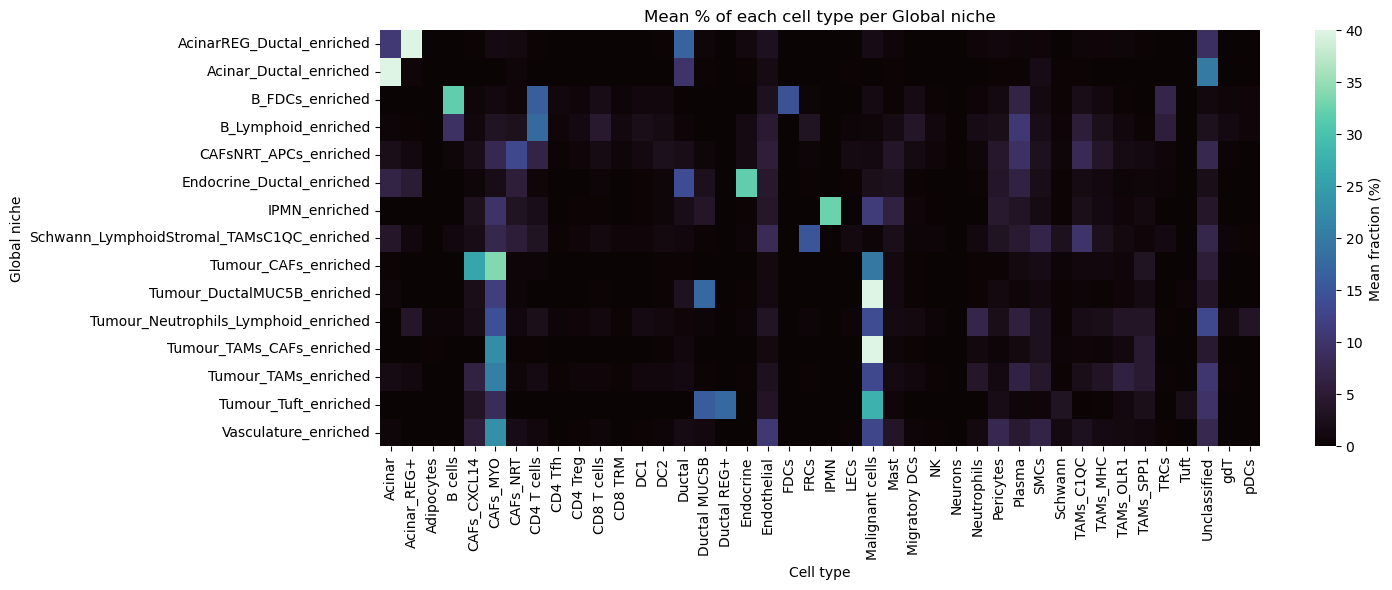

In [19]:
plt.figure(figsize=(15, 6))
sns.heatmap(niche_means_names * 100.0, cmap="mako", vmax=40, cbar_kws={"label": "Mean fraction (%)"}, linewidths=0)
plt.xlabel("Cell type"); plt.ylabel("Global niche"); plt.title("Mean % of each cell type per Global niche")
plt.tight_layout()
save("Niches_mean_fraction.pdf")
plt.show()

In [20]:
niche_means_names_z = pd.DataFrame(
    zscore(niche_means_names.values, axis=0, nan_policy="omit"),
    index=niche_means_names.index,
    columns=niche_means_names.columns
)

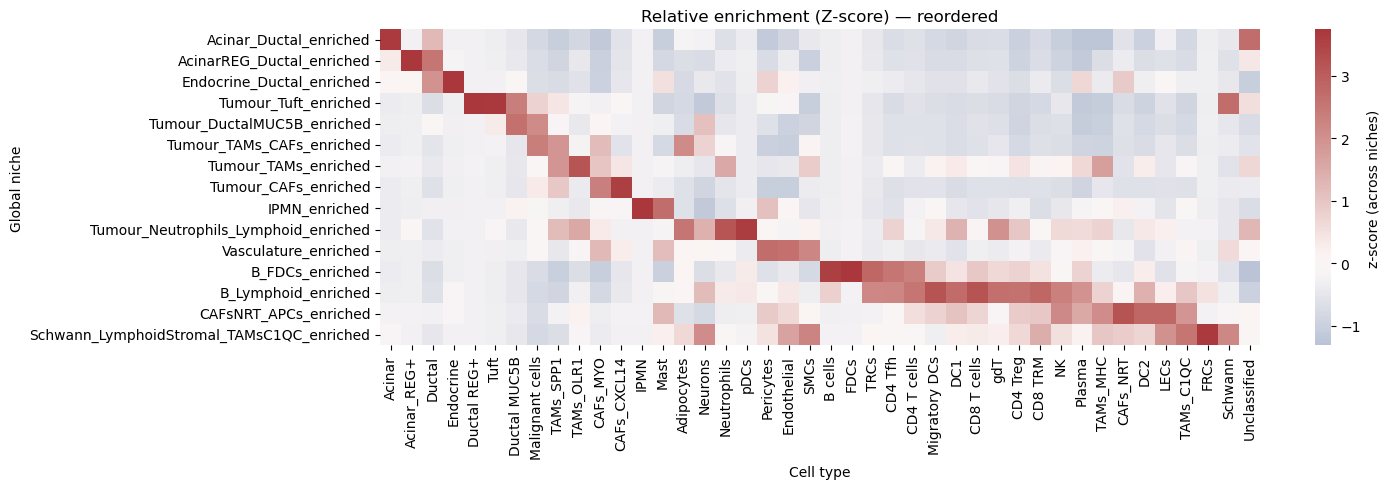

In [21]:
niche_order = ["Acinar_Ductal_enriched", "AcinarREG_Ductal_enriched",
               "Endocrine_Ductal_enriched", "Tumour_Tuft_enriched",
               "Tumour_DuctalMUC5B_enriched","Tumour_TAMs_CAFs_enriched",
              "Tumour_TAMs_enriched", "Tumour_CAFs_enriched", "IPMN_enriched",
               "Tumour_Neutrophils_Lymphoid_enriched","Vasculature_enriched",
               "B_FDCs_enriched", "B_Lymphoid_enriched", #"#aec7e8",
               "CAFsNRT_APCs_enriched", "Schwann_LymphoidStromal_TAMsC1QC_enriched",
               
               
                #"#8D747A",
               ] 

niche_order = [n for n in niche_order if n in niche_means_names_z.index]


cell_type_order = ["Acinar","Acinar_REG+","Ductal","Endocrine","Ductal REG+","Tuft","Ductal MUC5B",
                   "Malignant cells","TAMs_SPP1","TAMs_OLR1","CAFs_MYO","CAFs_CXCL14",
                   "IPMN","Mast",
                   "Adipocytes","Neurons","Neutrophils","pDCs",
                   "Pericytes","Endothelial", "SMCs",
                   "B cells", "FDCs", "TRCs","CD4 Tfh",
                   "CD4 T cells",
                   "Migratory DCs","DC1",
                   "CD8 T cells", "gdT",
                   "CD4 Treg","CD8 TRM","NK","Plasma","TAMs_MHC",
                   "CAFs_NRT","DC2","LECs","TAMs_C1QC","FRCs", 
                   "Schwann",
                   "Unclassified"
                   
]
cell_type_order = [ct for ct in cell_type_order if ct in niche_means_names_z.columns]

# Reorder DataFrame
#niche_means_z_reordered = niche_means_z.loc[niche_order, niche_means_z.columns[col_order]]
niche_means_z_reordered = niche_means_names_z.loc[niche_order, cell_type_order]

plt.figure(figsize=(15, 5))
sns.heatmap(
    niche_means_z_reordered,
    cmap="vlag",
    center=0,
    #vmax=3,
    #vmin=-1.5,
    cbar_kws={"label": "z-score (across niches)"},
    linewidths=0
)
plt.xlabel("Cell type")
plt.ylabel("Global niche")
plt.title("Relative enrichment (Z-score) — reordered")
plt.tight_layout()
save("Niches_composition_celltype_v2.pdf")
plt.show()

/tmp/ipykernel_16261/1617668536.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means_by_niche = dfX.join(combined.obs["global_niche_CLR"]).groupby("global_niche_CLR").mean() + eps


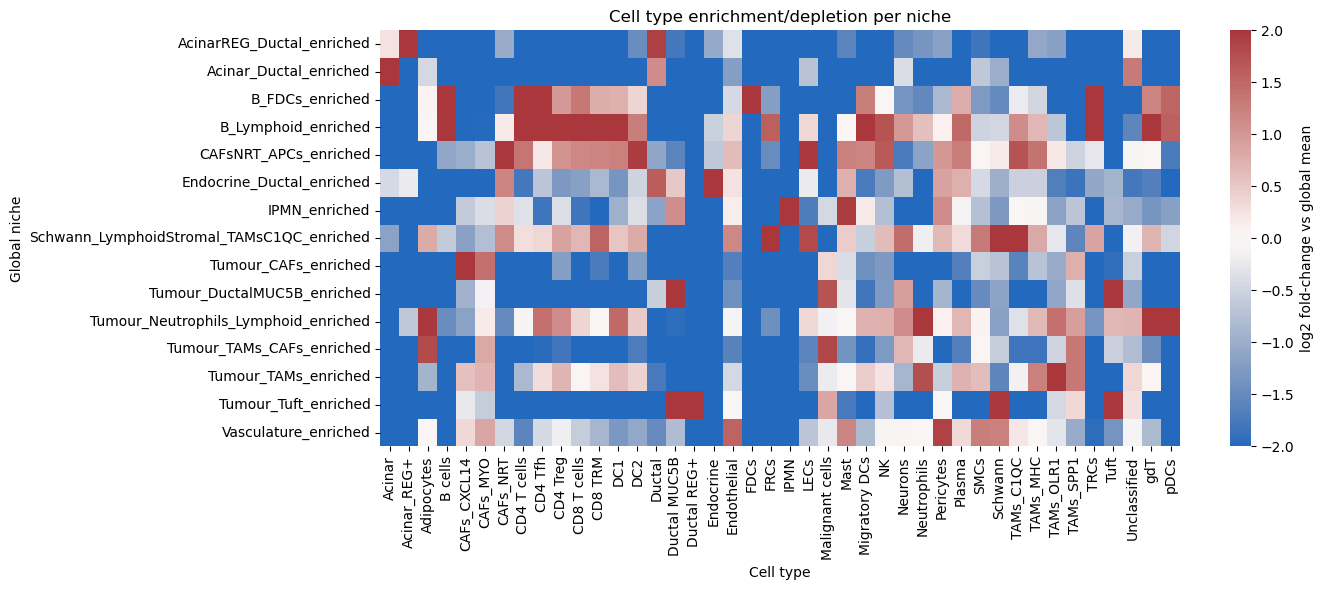

In [22]:
eps = 1e-9
means_by_niche = dfX.join(combined.obs["global_niche_CLR"]).groupby("global_niche_CLR").mean() + eps
log2fc = np.log2(means_by_niche.div(dfX.mean(0) + eps, axis=1))
plt.figure(figsize=(14, 6))
sns.heatmap(log2fc, cmap="vlag", center=0, vmin=-2, vmax=2, cbar_kws={"label": "log2 fold-change vs global mean"}, linewidths=0.0)
plt.xlabel("Cell type"); plt.ylabel("Global niche"); plt.title("Cell type enrichment/depletion per niche")
plt.tight_layout()
save("Niches_log2FC.pdf")
plt.show()

### Niches per sample

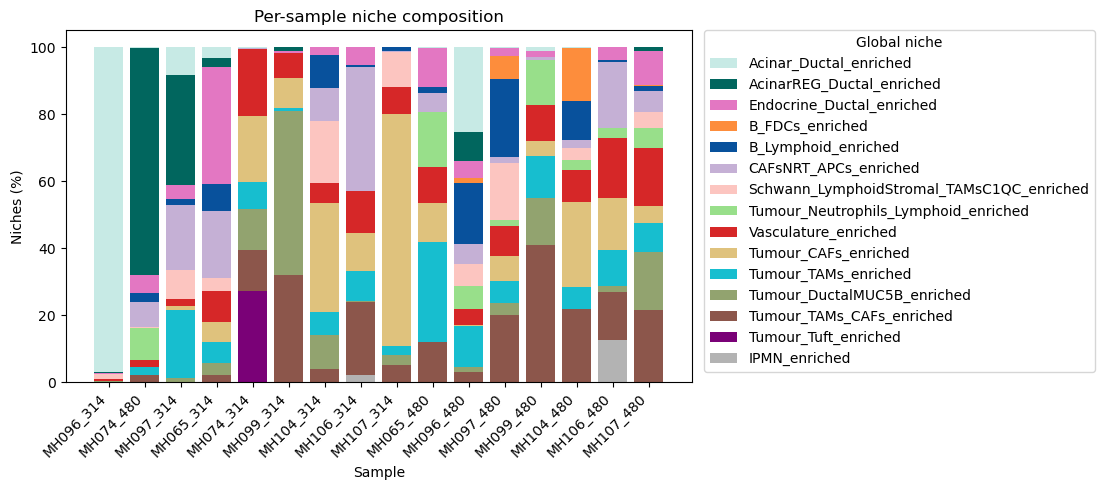

In [23]:
# count table: rows = samples, cols = niches
ct_counts = pd.crosstab(combined.obs["sample"], combined.obs["global_niche_CLR"])
ct_props  = ct_counts.div(ct_counts.sum(axis=1), axis=0) * 100  # row-wise %

niche_order =["Acinar_Ductal_enriched",
    "AcinarREG_Ductal_enriched",
    "Endocrine_Ductal_enriched",
    "B_FDCs_enriched",
    "B_Lymphoid_enriched", #"#aec7e8",
    "CAFsNRT_APCs_enriched",
    "Schwann_LymphoidStromal_TAMsC1QC_enriched",
    "Tumour_Neutrophils_Lymphoid_enriched",
    "Vasculature_enriched",  
    "Tumour_CAFs_enriched",
    "Tumour_TAMs_enriched",
    "Tumour_DuctalMUC5B_enriched",
    "Tumour_TAMs_CAFs_enriched",
    "Tumour_Tuft_enriched",
    "IPMN_enriched"]

sample_order = ["MH096_314","MH074_480","MH097_314","MH065_314",
                "MH074_314", "MH099_314", "MH104_314", "MH106_314", "MH107_314", 
                "MH065_480", "MH096_480", "MH097_480",
                "MH099_480", "MH104_480", "MH106_480", "MH107_480"]

# keep only those that exist; add any missing to the end (or drop)
niche_order = [n for n in niche_order if n in ct_props.columns] + \
              [n for n in ct_props.columns if n not in niche_order]

# reorder columns
ct_props = ct_props.reindex(columns=niche_order)

# Optional: define desired sample order
sample_order = [s for s in sample_order if s in ct_props.index]
ct_props = ct_props.loc[sample_order]

# consistent colors for niches
niches = ct_props.columns.astype(str)
palette = niche_color_map_clr

# stacked % bar chart (samples on x-axis)
fig, ax = plt.subplots(figsize=(max(10, 0.7*len(ct_props)), 5))

top = np.full(len(ct_props), 100.0)  # start at 100%
x = np.arange(len(ct_props))

for niche in niches:
    vals = ct_props[niche].values
    ax.bar(
        x,
        vals,
        bottom=top - vals,     # position so that we build downward
        label=niche,
        linewidth=0,
        color=palette[niche],
        width=0.8
    )
    top -= vals  

ax.set_xticks(x)
ax.set_xticklabels(ct_props.index, rotation=45, ha="right")
ax.set_ylabel("Niches (%)")
ax.set_xlabel("Sample")
ax.set_title("Per-sample niche composition")
ax.legend(title="Global niche", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0.)
save("Niches_composition_CLR_reorder.pdf")
fig.tight_layout()
plt.show()

/tmp/ipykernel_16261/2048342257.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  filtered.groupby(["global_niche_CLR", "sample"])
/tmp/ipykernel_16261/2048342257.py:45: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = get_cmap("tab20b", len(samples))


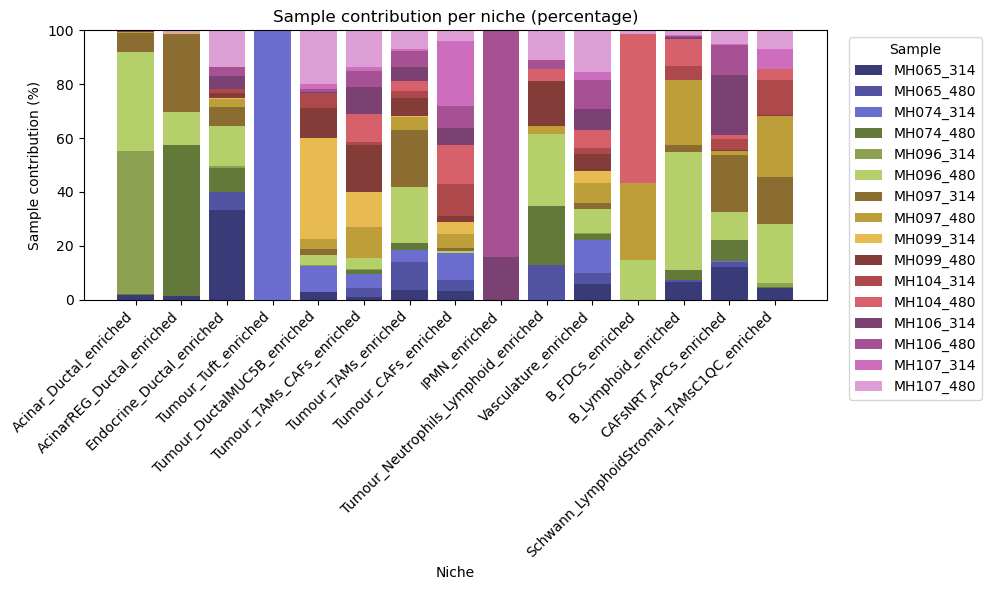

In [24]:
from matplotlib.cm import get_cmap

niche_order = ["Acinar_Ductal_enriched", "AcinarREG_Ductal_enriched",
               "Endocrine_Ductal_enriched", "Tumour_Tuft_enriched",
               "Tumour_DuctalMUC5B_enriched","Tumour_TAMs_CAFs_enriched",
              "Tumour_TAMs_enriched", "Tumour_CAFs_enriched", "IPMN_enriched",
               "Tumour_Neutrophils_Lymphoid_enriched","Vasculature_enriched",
               "B_FDCs_enriched", "B_Lymphoid_enriched", #"#aec7e8",
               "CAFsNRT_APCs_enriched", "Schwann_LymphoidStromal_TAMsC1QC_enriched"]


# 1. Filter out unclassified cells
label_col = "global_niche_CLR"
filtered = combined.obs.loc[
    ~combined.obs[label_col].isin(["Unclassified", "Unassigned"])
]

# 2. Group by niche and sample to get counts
counts_by_niche_sample = (
    filtered.groupby(["global_niche_CLR", "sample"])
            .size()
            .unstack(fill_value=0)  # rows = niches, columns = samples
)

# 3. Convert to percentages (row-wise)
counts_pct = counts_by_niche_sample.div(counts_by_niche_sample.sum(axis=1), axis=0) * 100

# Filter and reorder to include only the niches in your desired order
counts_pct = counts_pct.loc[
    counts_pct.index.intersection(niche_order)  
]

# Reording niche
counts_pct = counts_pct.reindex(niche_order)

# Reorder sample columns
sample_order = ["MH065_314", "MH065_480","MH074_314", "MH074_480","MH096_314","MH096_480",
                "MH097_314","MH097_480","MH099_314", "MH099_480","MH104_314","MH104_480",
                "MH106_314", "MH106_480","MH107_314", "MH107_480"
]


# 4. Set up color map for samples using "Paired"
samples = [s for s in sample_order if s in counts_pct.columns]
cmap = get_cmap("tab20b", len(samples))
sample_colors = {sample: cmap(i % cmap.N) for i, sample in enumerate(samples)}

# 5. Plot stacked percentage bar
fig, ax = plt.subplots(figsize=(max(10, 0.6 * len(counts_pct)), 6))

bottom = np.zeros(len(counts_pct))
x = np.arange(len(counts_pct))
niches = counts_pct.index

for sample in samples:
    vals = counts_pct[sample].values
    ax.bar(
        x, vals, bottom=bottom,
        label=sample,
        color=sample_colors[sample],
        width=0.8
    )
    bottom += vals

# Labeling
ax.set_xticks(x)
ax.set_xticklabels(niches, rotation=45, ha="right")
ax.set_ylabel("Sample contribution (%)")
ax.set_xlabel("Niche")
ax.set_title("Sample contribution per niche (percentage)")
ax.set_ylim(0, 100)
ax.legend(title="Sample", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
save("Samplecontributionperniche.pdf")
plt.show()

### Niches in each sample

In [12]:
def plot_niches(sample, niches=None, palette=niche_color_map_clr, xlim=None, ylim=None, name=None):
    ad_one = combined[combined.obs["sample"] == sample]
    df_plot = ad_one.obs.copy()
    df_plot[["x", "y"]] = np.asarray(ad_one.obsm["spatial"])
    if niches is not None:
        df_plot = df_plot[df_plot["global_niche_CLR"].isin(niches)].copy()
        df_plot["global_niche_CLR"] = df_plot["global_niche_CLR"].astype(str)
    plt.figure(figsize=(12, 12))
    sns.scatterplot(data=df_plot, x="x", y="y", hue="global_niche_CLR", palette=palette, s=1, rasterized=True, linewidth=0)
    plt.gca().set_aspect("equal")
    plt.gca().invert_yaxis()
    if xlim:
        plt.xlim(*xlim)
    if ylim:
        plt.ylim(*ylim)  # y-axis is inverted, so the first value is the bottom
    plt.title(f"{sample} — " + ("Selected Niche Clusters" if niches else "Niche K-means Clusters"))
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    save(name or f"Representative_niches_{sample}.pdf")
    plt.show()

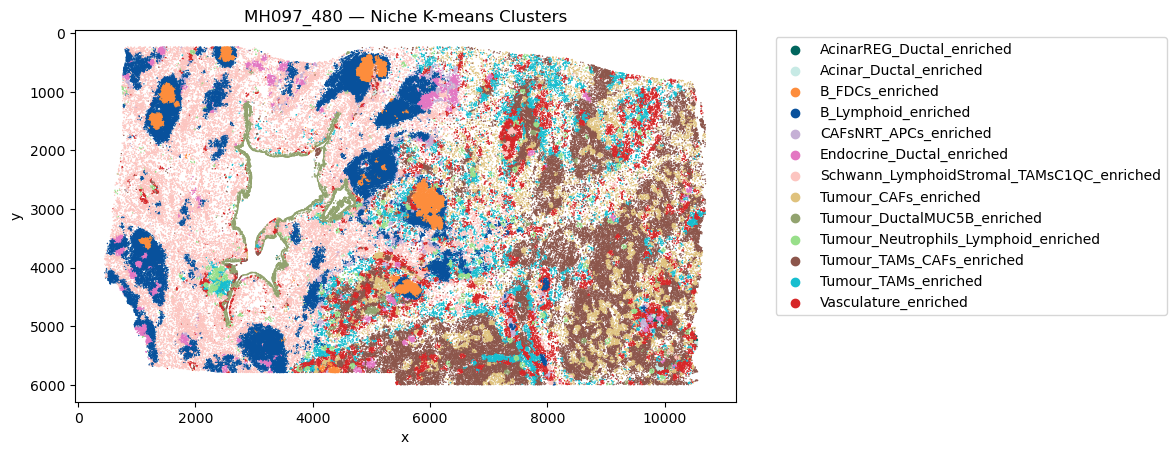

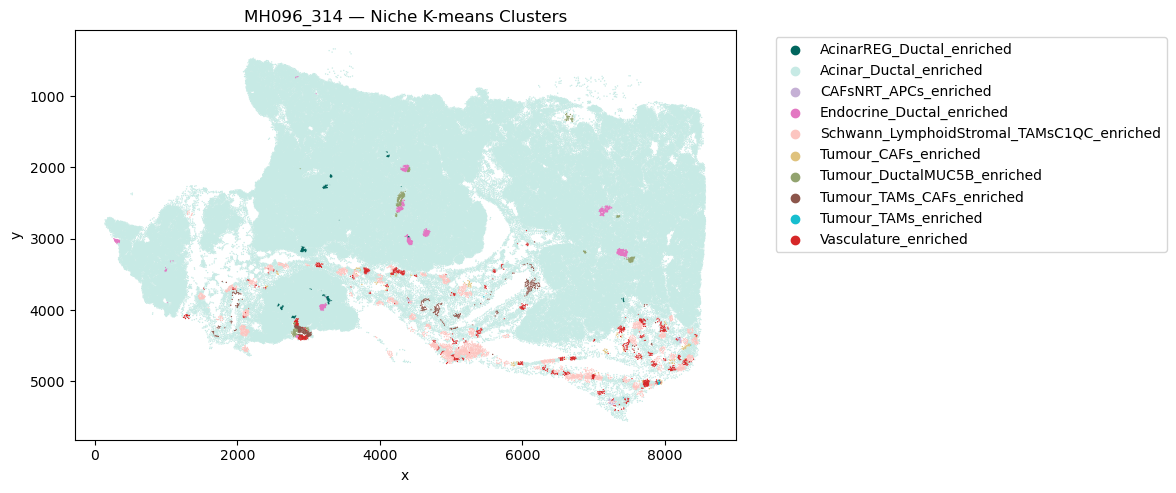

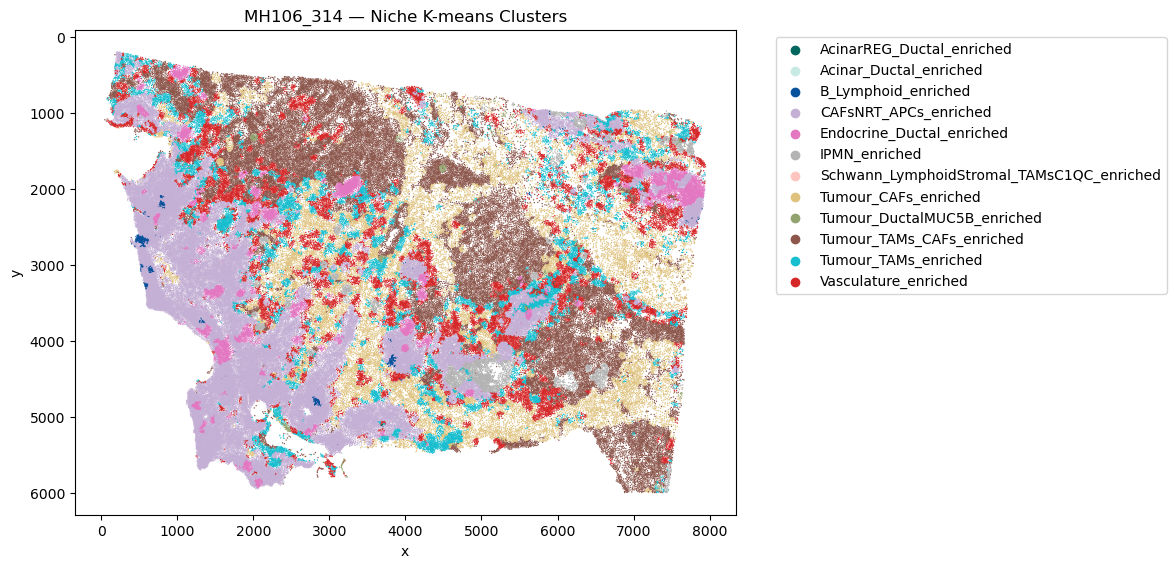

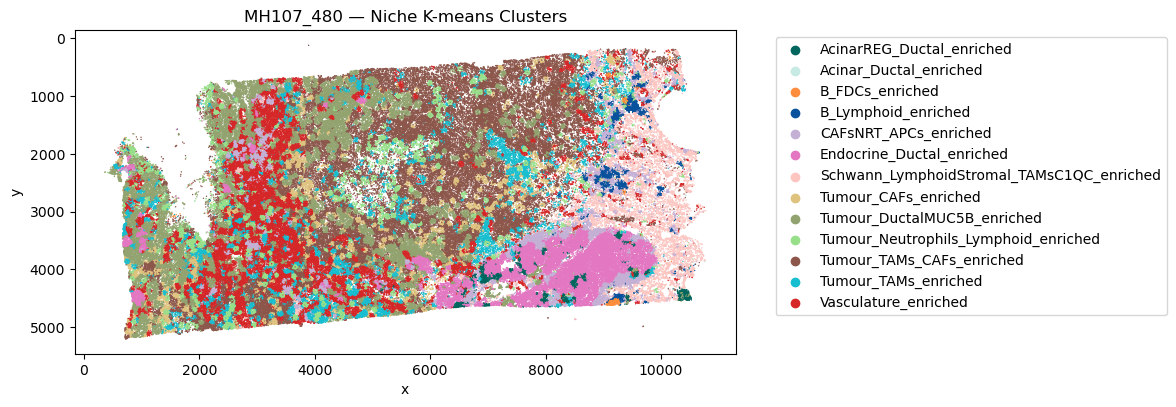

In [14]:
for sample in ["MH097_480","MH096_314","MH106_314","MH107_480"]:
    plot_niches(sample)

### Cell types in each niche

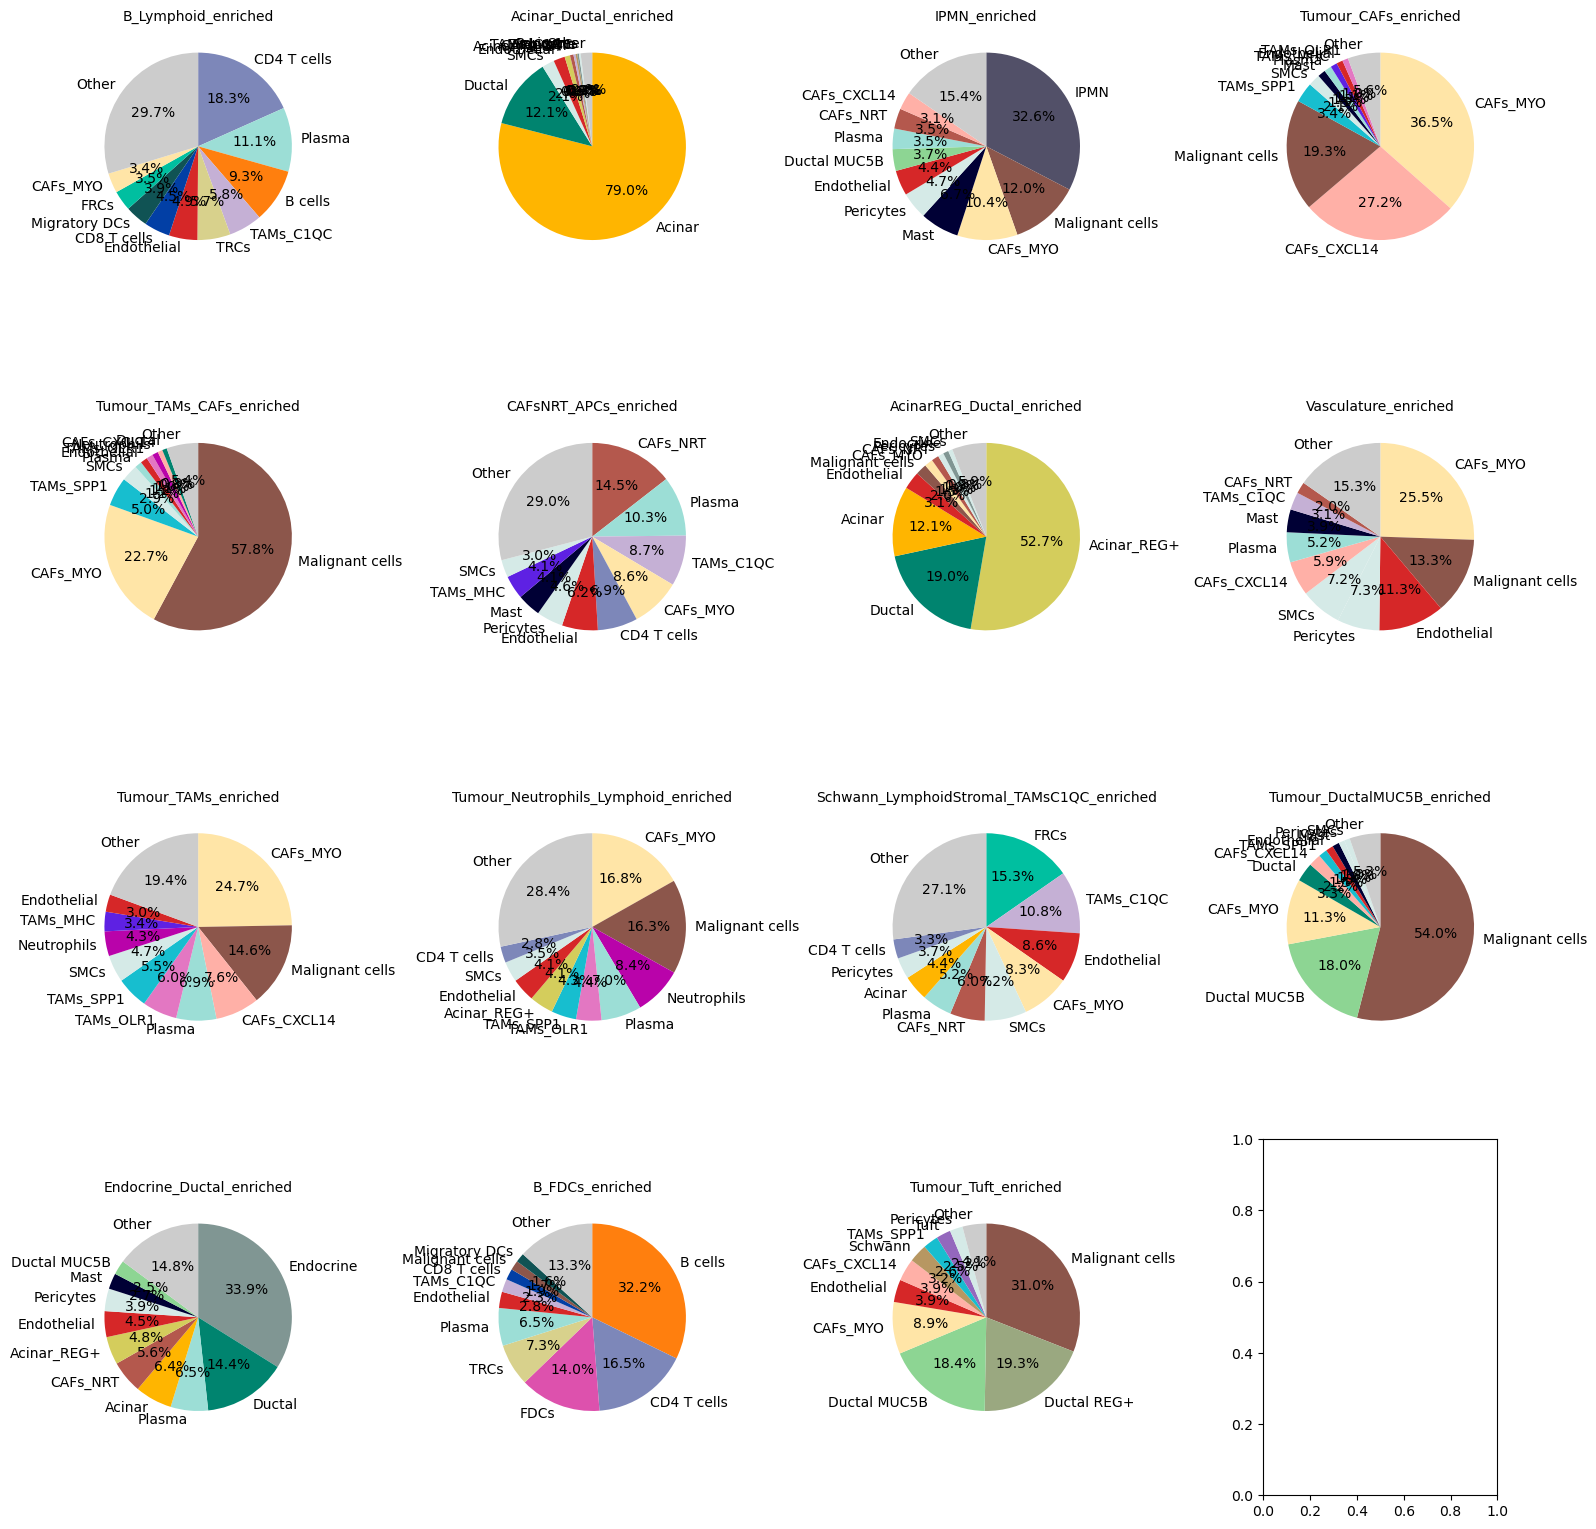

In [29]:
label_col = "cell_class_threshold"
all_niches = combined.obs["global_niche_CLR"].unique()
top_n = 10

# Prepare grid layout
n = len(all_niches)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4))
axes = axes.flatten()

for i, niche in enumerate(all_niches):
    ax = axes[i]

    # Filter data
    subset = combined.obs.loc[
        (combined.obs["global_niche_CLR"] == niche) &
        (~combined.obs[label_col].isin(["Unclassified", "Unassigned"]))
    ].copy()

    if subset.empty:
        ax.axis("off")
        continue

    # Compute proportions
    pct = (subset[label_col].value_counts(normalize=True) * 100).sort_values(ascending=False)

    top = pct.head(top_n)
    other = pct.iloc[top_n:].sum()
    if other > 0:
        top = pd.concat([top, pd.Series({"Other": other})])

    # Color mapping
    try:
        color_map = manual_colors.copy()
    except NameError:
        color_map = {}

    colors = []
    for ct in top.index:
        if ct == "Other":
            colors.append("#cccccc")
        else:
            colors.append(color_map.get(ct, None))

    # Assign fallback colors
    missing_idx = [i for i, c in enumerate(colors) if c is None]
    if missing_idx:
        pal = sns.color_palette("tab10", n_colors=len(missing_idx))
        for i_missing, p in zip(missing_idx, pal):
            colors[i_missing] = p

    # Plot
    ax.pie(
        top.values,
        labels=top.index,
        autopct="%1.1f%%",
        startangle=90,
        counterclock=False,
        colors=colors
    )
    ax.set_title(niche, fontsize=10)

plt.tight_layout()
save("PieCharts.pdf")
plt.show()

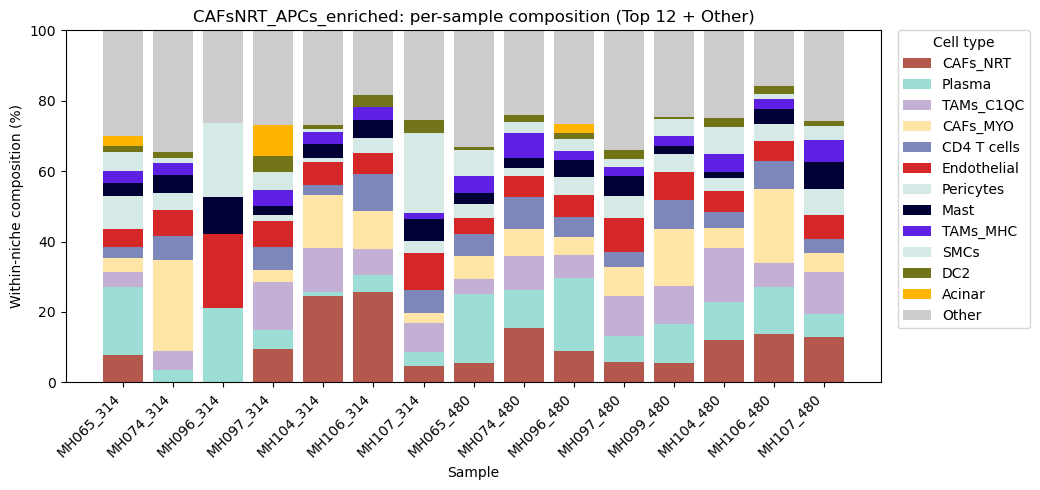

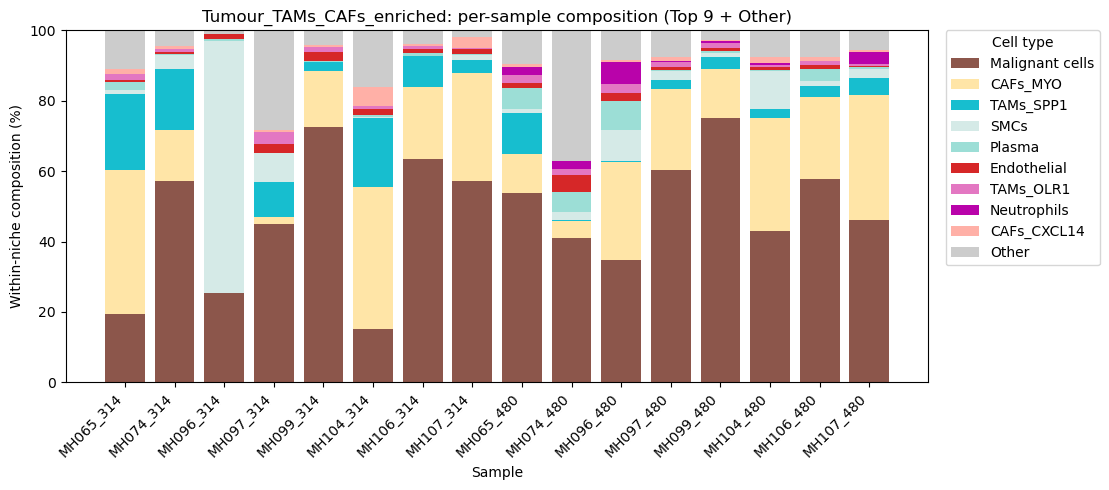

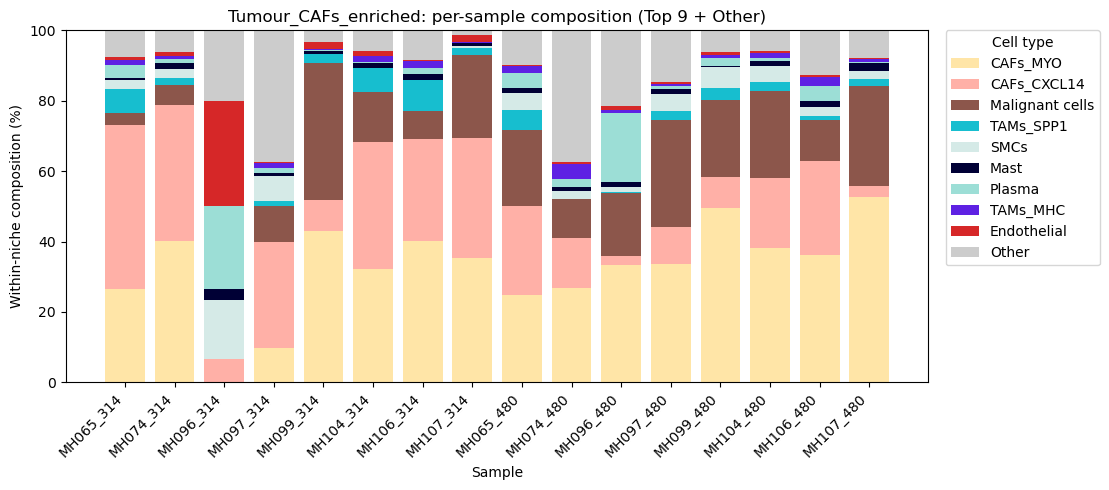

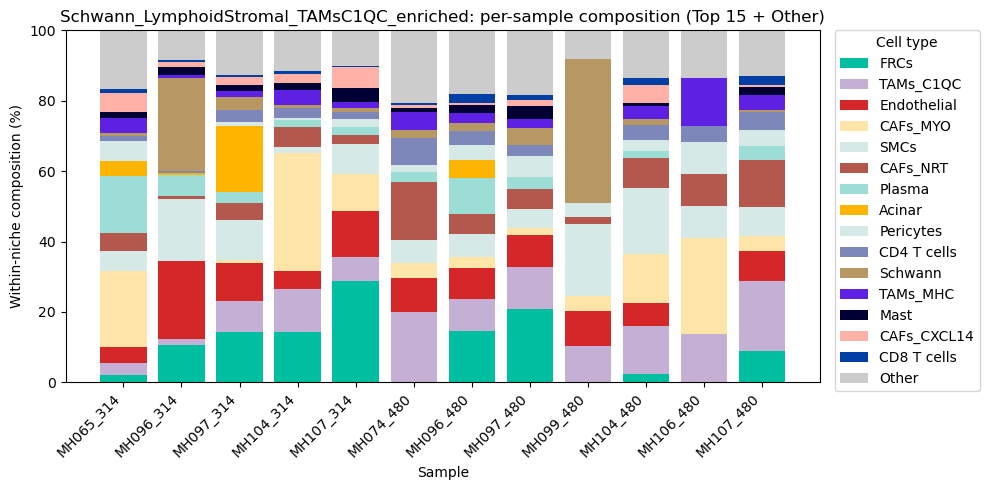

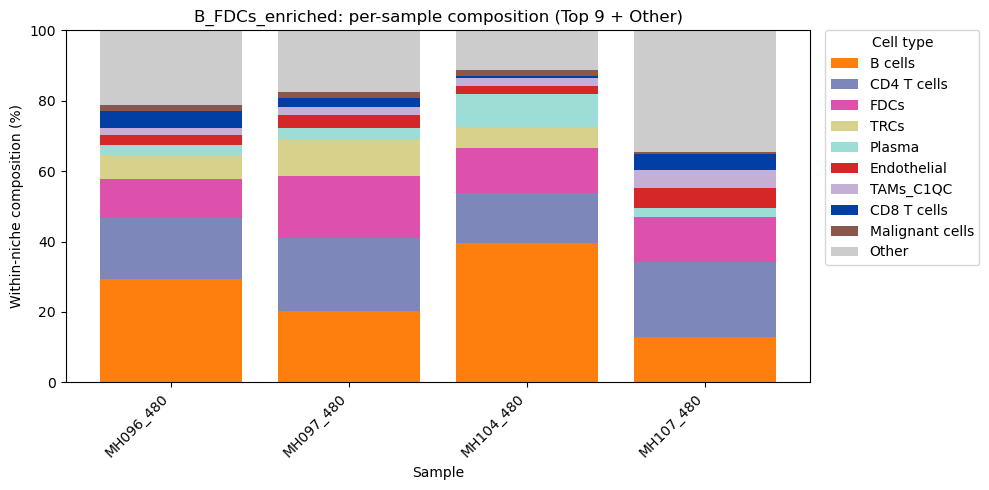

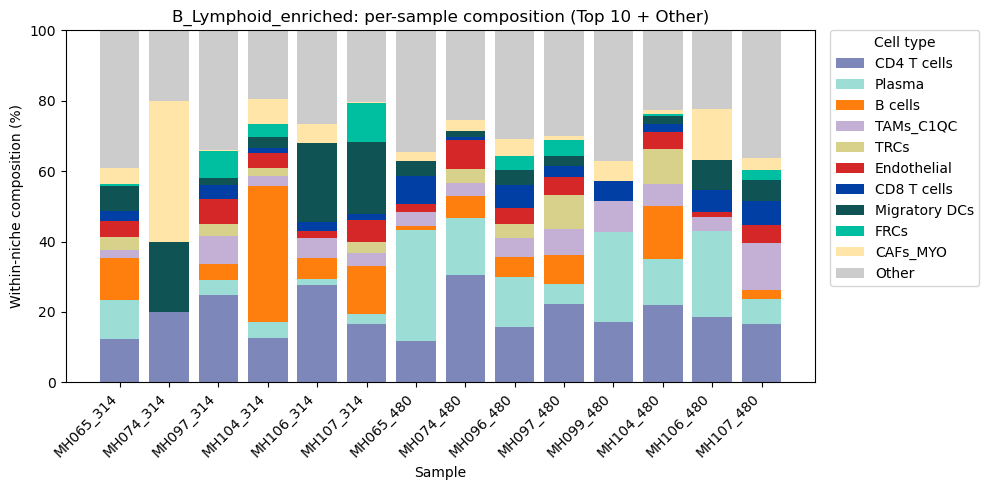

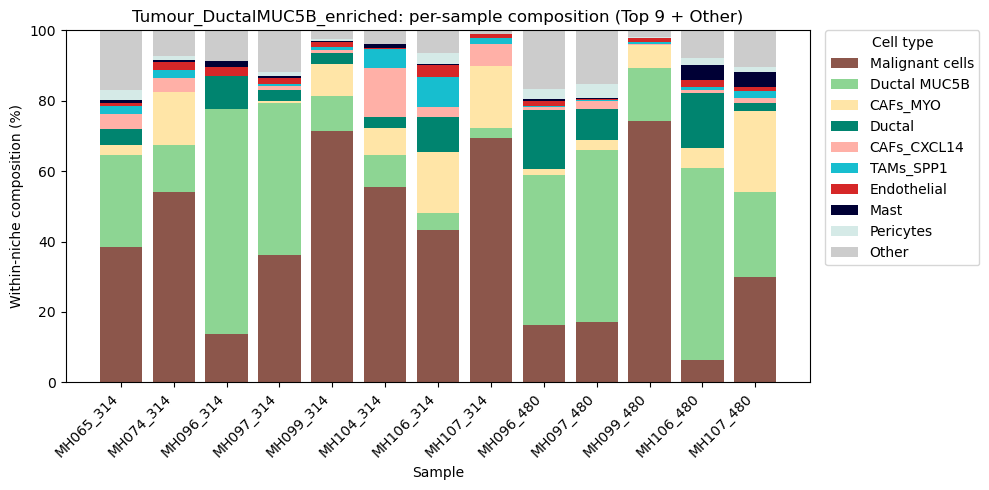

In [30]:
def niche_by_sample(niche, top_n, min_cell_types=None, label_col="cell_class_threshold"):
    """Per-sample composition of one niche: the top cell types and Other."""
    subset = combined.obs.loc[
        (combined.obs["global_niche_CLR"] == niche) & (~combined.obs[label_col].isin(["Unclassified", "Unassigned"]))
    ].copy()
    if subset.empty:
        raise ValueError(f"No cells found in niche '{niche}' after exclusions.")
    top = subset[label_col].value_counts().head(top_n).index.tolist()
    counts = subset.groupby(["sample", label_col], observed=True).size().unstack(fill_value=0)
    counts = counts[counts.sum(axis=1) > 0]
    if min_cell_types is not None:
        counts = counts[counts.astype(bool).sum(axis=1) > min_cell_types]
    for ct in top:
        if ct not in counts.columns:
            counts[ct] = 0
    perc = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100
    plot_df = perc[top].copy()
    plot_df["Other"] = (100 - perc[top].sum(axis=1)).clip(lower=0)
    plot_df = plot_df.fillna(0)

    fig, ax = plt.subplots(figsize=(max(10, 0.7 * len(plot_df)), 5))
    bottom, x = np.zeros(len(plot_df)), np.arange(len(plot_df))
    color_map = {**manual_colors, "Other": "#cccccc"}
    for col in top + ["Other"]:
        ax.bar(x, plot_df[col].values, bottom=bottom, label=col, color=color_map.get(col, "#cccccc"), width=0.8, linewidth=0)
        bottom += plot_df[col].values
    ax.set_xticks(x)
    ax.set_xticklabels(plot_df.index.astype(str), rotation=45, ha="right")
    ax.set_ylim(0, 100)
    ax.set_ylabel("Within-niche composition (%)"); ax.set_xlabel("Sample")
    ax.set_title(f"{niche}: per-sample composition (Top {top_n} + Other)")
    ax.legend(title="Cell type", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0.)
    fig.tight_layout()
    save(f"{niche}_acrossPatients.pdf")
    plt.show()


# Top cell types shown for each niche, and whether samples with 3 or fewer cell types are left out
for niche, top_n, min_cell_types in [
    ("CAFsNRT_APCs_enriched", 12, None),
    ("Tumour_TAMs_CAFs_enriched", 9, None),
    ("Tumour_CAFs_enriched", 9, None),
    ("Schwann_LymphoidStromal_TAMsC1QC_enriched", 15, 3),
    ("B_FDCs_enriched", 9, 3),
    ("B_Lymphoid_enriched", 10, 3),
    ("Tumour_DuctalMUC5B_enriched", 9, 3),
]:
    niche_by_sample(niche, top_n, min_cell_types)

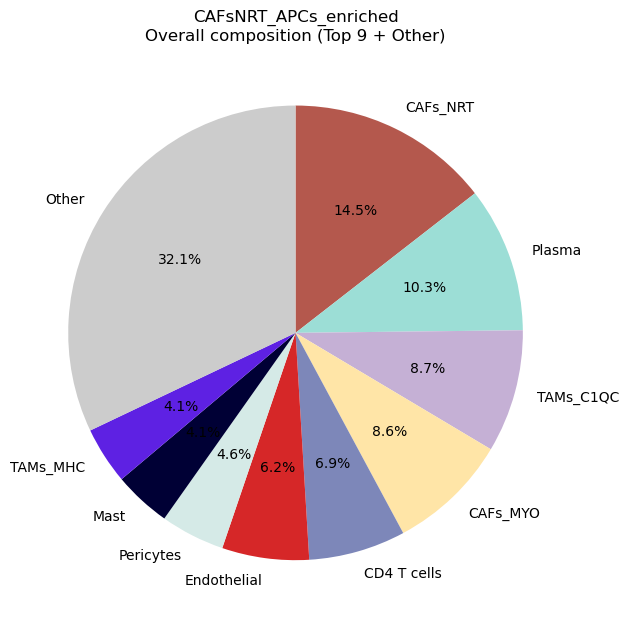

CAFs_NRT       14.48
Plasma         10.34
TAMs_C1QC       8.74
CAFs_MYO        8.59
CD4 T cells     6.89
Endothelial     6.18
Pericytes       4.57
Mast            4.07
TAMs_MHC        4.07
Other          32.06
Name: percent, dtype: float64

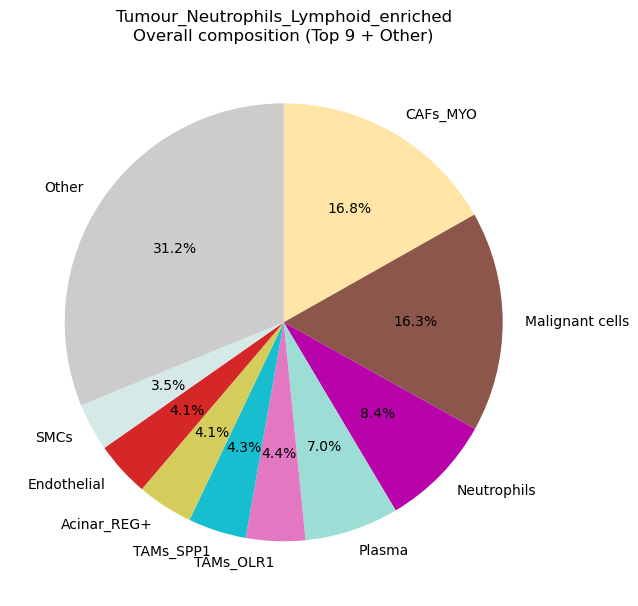

CAFs_MYO           16.82
Malignant cells    16.27
Neutrophils         8.36
Plasma              6.95
TAMs_OLR1           4.37
TAMs_SPP1           4.30
Acinar_REG+         4.13
Endothelial         4.06
SMCs                3.54
Other              31.19
Name: percent, dtype: float64

In [31]:
def niche_pie(niche, top_n=9, label_col="cell_class_threshold"):
    subset = combined.obs.loc[
        (combined.obs["global_niche_CLR"] == niche) & (~combined.obs[label_col].isin(["Unclassified", "Unassigned"]))
    ]
    pct = (subset[label_col].value_counts(normalize=True) * 100).sort_values(ascending=False)
    top = pct.head(top_n)
    if pct.iloc[top_n:].sum() > 0:
        top = pd.concat([top, pd.Series({"Other": pct.iloc[top_n:].sum()})])
    colors = [manual_colors.get(ct, "#cccccc") for ct in top.index]
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.pie(top.values, labels=top.index, autopct="%1.1f%%", startangle=90, counterclock=False, colors=colors)
    ax.set_title(f"{niche}\nOverall composition (Top {top_n} + Other)")
    plt.tight_layout()
    save(f"{niche}_top{top_n}_pie.pdf")
    plt.show()
    return top.round(2).rename("percent")


for niche in ["CAFsNRT_APCs_enriched", "Tumour_Neutrophils_Lymphoid_enriched"]:
    display(niche_pie(niche))